# 30회 후기 유형 연습 해설

공식 원문·정답이 아닌 창작 합성 자료입니다. README와 출처·보완 명세를 먼저 확인하세요. Python 3.12 별도 실행 환경을 사용합니다. 아래 문제 지문은 PDF와 같으며 설명 셀의 선택 근거·가정·가설과 실행 출력의 계산값·기각 여부·상황 결론을 함께 읽으세요. `분석코드.py`로 같은 계산을 일괄 실행할 수 있습니다.

In [1]:
from pathlib import Path
import sys
FOLDER = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
repo = next(p for p in [FOLDER]+list(FOLDER.parents) if (p/'tools/exams').is_dir())
sys.path.insert(0,str(repo/'기출문제/유형연습/공통'))
from analysis import Context
ctx=Context(FOLDER)


## 1. 건강검진 자료의 혈압 예측

health.csv는 독립 성인의 나이·체중·허리둘레·안정시 심박수와 DBP(이완기 혈압)다. id는 식별자다. 미래 대상 예측이 목적이며 1번 전체에 같은 자료·분할을 사용한다. 의학적 인과 효과를 주장하지 않는다.

### 1-1

**문제** 결측·극단값·변수 분포와 관계를 조사하시오. seed=30으로 7:3 분할하고, 학습/평가 자료의 타깃 분포와 대치 기준의 적용 범위를 설명하시오.

**풀이·선택 근거·해석**

평가 자료를 먼저 분리하고 대치·표준화는 학습 폴드 안에서 적합한다. 극단값의 존재만으로 삭제하지 않는다. 분할의 대표성과 모집단 차이는 별개다.


=== 1-1 ===
missing
{
  "id": 0,
  "age": 0,
  "weight": 11,
  "waist": 0,
  "pulse": 0,
  "DBP": 0
}
distributions
{
  "train": {
    "count": 168.0,
    "mean": 80.29160712619048,
    "std": 6.7264791088027645,
    "min": 60.8251202,
    "25%": 74.84411435,
    "50%": 80.6626481,
    "75%": 84.89658115,
    "max": 99.109601
  },
  "test": {
    "count": 72.0,
    "mean": 79.36435977083332,
    "std": 6.456870136898658,
    "min": 64.9053972,
    "25%": 74.350421375,
    "50%": 79.53196345,
    "75%": 83.828729725,
    "max": 98.4128128
  }
}


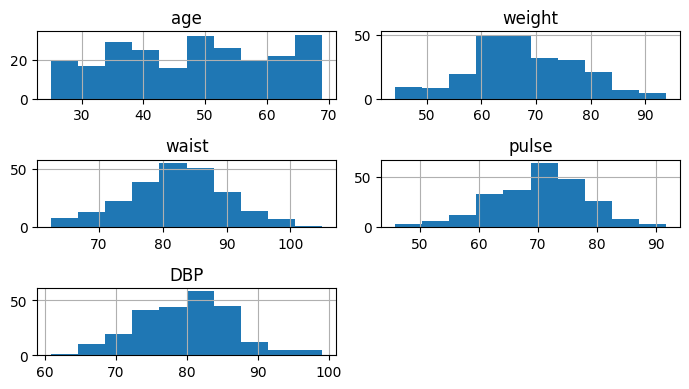

In [2]:
ctx.run('1-1', 'health_eda')

### 1-2

**문제** 특성의 중복성을 조사하고 차원을 줄일 필요가 있는지 설명하시오. 학습 자료에서 분산 90%를 보존하는 표현을 만들고 원 변수의 해석 가능성과 비교하시오.

**풀이·선택 근거·해석**

표준화한 학습 자료의 PCA를 사용한다. 차원 감소는 예측 향상을 보장하지 않으며 시험 자료로 차원 수를 고르지 않는다.

In [3]:
ctx.run('1-2', 'health_pca')


=== 1-2 ===
training correlation
[
  {
    "index": "age",
    "age": 1.0,
    "weight": 0.0255194102308078,
    "waist": -0.028064675093473667,
    "pulse": 0.05063784228863952
  },
  {
    "index": "weight",
    "age": 0.0255194102308078,
    "weight": 1.0,
    "waist": 0.9064721033819347,
    "pulse": 0.03128170402326516
  },
  {
    "index": "waist",
    "age": -0.028064675093473667,
    "weight": 0.9064721033819347,
    "waist": 1.0,
    "pulse": 0.05632874440773141
  },
  {
    "index": "pulse",
    "age": 0.05063784228863952,
    "weight": 0.03128170402326516,
    "waist": 0.05632874440773141,
    "pulse": 1.0
  }
]
PCA
{
  "n": 3,
  "variance_ratio": [
    0.47229034117822344,
    0.2621907939575457,
    0.23724662593648174
  ]
}


### 1-3

**문제** 혈압을 설명하는 선형모형을 적합하고 전체 가설·통계량·p-value·기각 여부를 작성하시오. 잔차 그림과 정규성·등분산성 진단을 제시하고 모형 유의성과 가정 충족의 차이를 설명하시오.

**풀이·선택 근거·해석**

전체 F검정 H0는 절편 외 계수 모두 0이다. 잔차 정규성·등분산성 검정은 각각 별도 H0를 가진다. F 유의성은 선형성의 증명이 아니다.


=== 1-3 ===
coefficients
[
  {
    "index": "const",
    "coef": 34.643683220264926,
    "SE": 4.246997044224572,
    "t": 8.157218585159214,
    "p": 8.732512125502126e-14
  },
  {
    "index": "age",
    "coef": 0.38194893429560783,
    "SE": 0.022057903414476245,
    "t": 17.31574062677874,
    "p": 8.894004950194298e-39
  },
  {
    "index": "weight",
    "coef": 0.19511630966389876,
    "SE": 0.06155384232150164,
    "t": 3.169847767500646,
    "p": 0.0018220501288137745
  },
  {
    "index": "waist",
    "coef": 0.1295907398955274,
    "SE": 0.07878155276766843,
    "t": 1.6449376198219696,
    "p": 0.10190979290224689
  },
  {
    "index": "pulse",
    "coef": 0.04652853077049407,
    "SE": 0.03610914909367011,
    "t": 1.2885524012154155,
    "p": 0.19937968184077223
  }
]
fit
{
  "R2": 0.7180623341233243,
  "n": 168.0
}
{
  "method": "OLS overall F",
  "H0": "all slopes=0",
  "H1": "at least one slope != 0",
  "statistic": 103.7854946572649,
  "p_value": 9.16549125556798e-44,

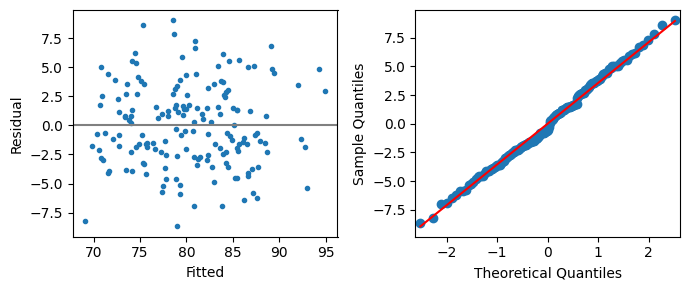

In [4]:
ctx.run('1-3', 'health_ols')

### 1-4

**문제** 선형·트리·부스팅 모형을 학습 자료 내부 3-fold CV의 RMSE로 비교하시오. 선택 모형을 전체 학습 자료에 다시 적합해 보류 자료 RMSE·MAE·R²를 보고하고 평가값의 한계를 설명하시오.

**풀이·선택 근거·해석**

모형 선택에는 CV만 사용한다. 각 폴드 안에서 전처리를 적합하고 선택이 끝난 뒤 보류 자료를 한 번 평가한다. CV 최저점은 선택에 따른 낙관성이 있다.

In [5]:
ctx.run('1-4', 'health_models')


=== 1-4 ===
CV selection
{
  "scores": {
    "Linear": 3.7598429100247777,
    "RF": 4.241025103965349,
    "GB": 4.089364546559878
  },
  "chosen": "Linear",
  "metric": "RMSE",
  "selection": "training CV only"
}
holdout
{
  "RMSE": 5.128773092143734,
  "MAE": 3.925138817908765,
  "R2": 0.36018117358292656,
  "n": 72
}
split IDs
{
  "train_index": [
    118,
    225,
    155,
    196,
    6,
    184,
    5,
    61,
    139,
    17,
    111,
    0,
    96,
    12,
    3,
    171,
    227,
    2,
    150,
    84,
    224,
    72,
    112,
    42,
    187,
    123,
    31,
    218,
    190,
    38,
    122,
    114,
    86,
    68,
    94,
    97,
    232,
    73,
    23,
    81,
    125,
    89,
    56,
    14,
    32,
    51,
    176,
    93,
    126,
    41,
    230,
    66,
    181,
    82,
    76,
    160,
    70,
    83,
    30,
    74,
    159,
    182,
    214,
    115,
    170,
    124,
    146,
    210,
    228,
    29,
    198,
    152,
    80,
    108,
    201,
    217,
   

## 2. 사고 유형 분류

accident.csv는 독립 사고의 date·weather·road·speed와 severe(0/1)다. 건강 자료와 별도 자료다. id mod 5=0을 보류 평가로 고정한다. 기준은 weather=clear, road=urban이다.

### 2-1

**문제** 주말 여부를 생성하고 범주형 특성과 사고 심각도의 관계를 평가하시오. 두 관계의 검정 방법·가정·가설·원/보정 p-value·기각 여부와 결론을 제시하시오.

**풀이·선택 근거·해석**

독립 도수표의 관계는 카이제곱 독립성 검정으로 평가하고 기대도수 조건을 확인한다. 두 탐색 관계는 Holm 보정한다. 관계는 원인 효과가 아니다.

In [6]:
ctx.run('2-1', 'accident_tests')


=== 2-1 ===
weather_table
[
  {
    "weather": "clear",
    "0": 82,
    "1": 20
  },
  {
    "weather": "rain",
    "0": 66,
    "1": 24
  }
]
weather_expected
[
  [
    78.625,
    23.375
  ],
  [
    69.375,
    20.625
  ]
]
{
  "method": "Pearson independence weather-severe",
  "H0": "weather independent of severe",
  "H1": "weather associated with severe",
  "statistic": 1.3486341956930192,
  "p_value": 0.2455170305219953,
  "df": 1,
  "alpha": 0.05,
  "reject_H0": false,
  "conclusion": "유의수준 5%에서 weather와 severe의 관련성에 대한 근거가 충분하지 않다.",
  "adjusted_p_value": 0.4910340610439906
}
road_table
[
  {
    "road": "rural",
    "0": 64,
    "1": 23
  },
  {
    "road": "urban",
    "0": 84,
    "1": 21
  }
]
road_expected
[
  [
    67.0625,
    19.9375
  ],
  [
    80.9375,
    24.0625
  ]
]
{
  "method": "Pearson independence road-severe",
  "H0": "road independent of severe",
  "H1": "road associated with severe",
  "statistic": 1.1159196814369228,
  "p_value": 0.29079875156993984,
  

### 2-2

**문제** 불균형 대응 방법을 선택하고 타당성을 설명하시오. 범주값이 훼손되지 않는 학습 표본 보완을 적용하고 전후 클래스 수를 보고하시오. 인코딩된 범주에 일반 수치형 합성을 적용할 때의 위험을 설명하시오.

**풀이·선택 근거·해석**

여기서는 원 표본을 복제하는 RandomOverSampler를 선택해 범주값을 보존한다. CV 안에서만 보완한다. SMOTE-NC 등 다른 타당한 대안도 가능하다. 단순 범주 코드를 연속 거리처럼 합성하지 않는다.

In [7]:
ctx.run('2-2', 'accident_sampling')


=== 2-2 ===
class counts
{
  "before": {
    "0": 148,
    "1": 44
  },
  "after": {
    "0": 148,
    "1": 148
  }
}


### 2-3

**문제** 선형 확률점수 모형과 비선형 앙상블을 동일한 학습 내부 CV의 F1으로 비교하시오. 최종 보류 F1·ROC-AUC·ROC 그림을 제시하고 기준 범주 대비 계수의 오즈비 또는 특성 중요도를 해석하시오.

**풀이·선택 근거·해석**

Logistic과 RF를 같은 CV로 비교한다. ROC는 예측 클래스가 아닌 positive 확률로 작성한다. 임계값은 사전 0.5 고정, 계수와 RF 중요도의 단위·편향을 구분한다.


=== 2-3 ===
CV selection
{
  "scores": {
    "Logistic": 0.4241958289148109,
    "RF": 0.30426806897395137
  },
  "chosen": "Logistic",
  "metric": "f1",
  "selection": "training CV only"
}


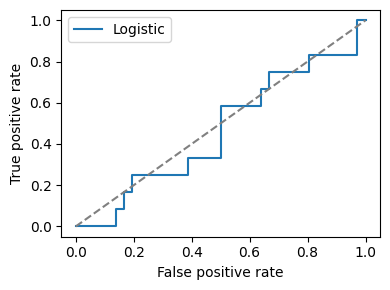

holdout
{
  "F1": 0.3783783783783784,
  "confusion_matrix": [
    [
      18,
      18
    ],
    [
      5,
      7
    ]
  ],
  "classification_report": {
    "0": {
      "precision": 0.782608695652174,
      "recall": 0.5,
      "f1-score": 0.6101694915254238,
      "support": 36.0
    },
    "1": {
      "precision": 0.28,
      "recall": 0.5833333333333334,
      "f1-score": 0.3783783783783784,
      "support": 12.0
    },
    "accuracy": 0.5208333333333334,
    "macro avg": {
      "precision": 0.531304347826087,
      "recall": 0.5416666666666667,
      "f1-score": 0.4942739349519011,
      "support": 48.0
    },
    "weighted avg": {
      "precision": 0.6569565217391304,
      "recall": 0.5208333333333334,
      "f1-score": 0.5522217132386624,
      "support": 48.0
    }
  },
  "n": 48,
  "AUC": 0.462962962962963
}
Logistic odds ratios (scaled numeric units)
[
  [
    1.9421562259453053,
    0.9437183195668676,
    1.7831360782056698,
    1.0147319573533007
  ]
]
split IDs
{


In [8]:
ctx.run('2-3', 'accident_models')

## 3. 물류·판매 의사결정

수송은 transport.json의 단위 운송비·공급·수요를 사용한다. 연령-제품 자료는 headset.csv의 독립 고객 관측이며 별도 과제다. 확률 문제의 독립성은 명시한 대로 가정한다.

### 3-1

**문제** 운송량을 결정변수로 정의하고 공급·수요·비음수 제약을 세워 총 운송비가 최소인 배분을 구하시오. 제약 충족·목적값과 최적성 근거를 제시하시오.

**풀이·선택 근거·해석**

선형계획의 수송문제다. 공급 합=수요 합인 균형 문제이며 행·열 합을 검증한다. 풀이 성공 상태와 원/쌍대 목적값을 대조한다. 가설검정 문제는 아니다.

In [9]:
ctx.run('3-1', 'transport')


=== 3-1 ===
plan
{
  "amount": [
    [
      30.0,
      0.0,
      0.0
    ],
    [
      5.0,
      35.0,
      0.0
    ],
    [
      5.0,
      0.0,
      45.0
    ]
  ],
  "cost": 370.0,
  "dual_objective": 370.0,
  "primal_dual_gap": 0.0,
  "dual_variables": [
    4.0,
    5.0,
    6.0,
    -0.0,
    -2.0,
    -4.0
  ],
  "reduced_cost": [
    0.0,
    6.0,
    6.0,
    0.0,
    0.0,
    6.0,
    0.0,
    1.0,
    0.0
  ],
  "success": true,
  "supply": [
    30,
    40,
    50
  ],
  "demand": [
    40,
    35,
    45
  ]
}


### 3-2

**문제** 연령대와 헤드셋 선호가 관련 있는지 판단하시오. 방법·근거·가정·H0/H1·통계량·자유도·p-value·기각 여부·마케팅 맥락의 결론을 작성하시오.

**풀이·선택 근거·해석**

독립 고객의 범주형 도수표다. 기대도수 조건을 확인해 전체 독립성 검정을 수행한다. 비기각은 독립성의 증명이 아니다.

In [10]:
ctx.run('3-2', 'headset')


=== 3-2 ===
age_group_table
[
  {
    "age_group": "middle",
    "wired": 44,
    "wireless": 49
  },
  {
    "age_group": "senior",
    "wired": 36,
    "wireless": 23
  },
  {
    "age_group": "young",
    "wired": 23,
    "wireless": 65
  }
]
age_group_expected
[
  [
    39.9125,
    53.0875
  ],
  [
    25.320833333333333,
    33.67916666666667
  ],
  [
    37.766666666666666,
    50.233333333333334
  ]
]
{
  "method": "Pearson independence age_group-preference",
  "H0": "age_group independent of preference",
  "H1": "age_group associated with preference",
  "statistic": 18.738074610133907,
  "p_value": 8.532549131168518e-05,
  "df": 2,
  "alpha": 0.05,
  "reject_H0": true,
  "conclusion": "유의수준 5%에서 age_group와 preference의 관련성에 대한 근거가 있다."
}


### 3-3

**문제** 독립인 5가족이 각각 자녀 6명을 가지며 각 자녀가 딸일 확률은 독립적으로 0.5다. 딸이 4명 이상인 가족이 3가족 이상일 확률과 그러한 가족 수의 기댓값을 구하시오.

**풀이·선택 근거·해석**

먼저 q=P(Bin(6,.5)≥4), 다음 Y~Bin(5,q)다. 가족 내 사건과 가족 간 사건을 구분한다. 기대 가족 수는 5q다.

In [11]:
ctx.run('3-3', 'binomial')


=== 3-3 ===
probability
{
  "q": 0.34375,
  "P_at_least_3_families": 0.2255459427833557,
  "expected_families": 1.71875
}
